In [19]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

df = pd.read_csv('/content/youtube-top-100-songs-2025.csv')

# Menggunakan kolom 'view_count' (jumlah views 100 lagu)
data = df['view_count'].values
n = len(data)

print(f"Data berhasil dimuat! Jumlah sampel: {n}")
print(f"5 Data Pertama (View Count):\n{data[:5]}")

Data berhasil dimuat! Jumlah sampel: 100
5 Data Pertama (View Count):
[2009014557 1324833300    2536628  558329099    2113548]


In [20]:
# ESTIMASI TITIK DAN INTERVAL (DISTRIBUSI Z, 5%)

mean_sampel = np.mean(data)
std_sampel = np.std(data, ddof=1) # Standard deviasi sampel

# Tingkat kesalahan (alpha) = 5% -> Tingkat Kepercayaan (Confidence Level) = 95%
alpha = 0.05
z_critical = stats.norm.ppf(1 - alpha/2)  # Nilai Z Kritis (sekitar 1.96)

# Standar error & Margin of Error (Z)
std_error = std_sampel / np.sqrt(n)
margin_of_error = z_critical * std_error

# Interval Kepercayaan Z (95%)
ci_lower = mean_sampel - margin_of_error
ci_upper = mean_sampel + margin_of_error

print("\n--- HASIL BAGIAN A ---")
print(f"1. Estimasi Titik (Rata-rata Sampel): {mean_sampel:,.2f} views")
print(f"2. Nilai Kritis Z (95%): {z_critical:.4f}")
print(f"3. Margin of Error: ±{margin_of_error:,.2f}")
print(f"4. Estimasi Interval Z (95%): ({ci_lower:,.2f}, {ci_upper:,.2f}) views")


--- HASIL BAGIAN A ---
1. Estimasi Titik (Rata-rata Sampel): 105,910,319.07 views
2. Nilai Kritis Z (95%): 1.9600
3. Margin of Error: ±48,825,283.36
4. Estimasi Interval Z (95%): (57,085,035.71, 154,735,602.43) views


In [21]:
# RESAMPLING (JACKKNIFE & BOOTSTRAPPING 1000 ITERASI)

# A. Jackknife
jackknife_means = np.zeros(n)
for i in range(n):
    # Buat sampel dengan menghapus 1 observasi (Leave-One-Out)
    sample_jack = np.delete(data, i)
    jackknife_means[i] = np.mean(sample_jack)

mean_jackknife = np.mean(jackknife_means)

# B. Bootstrapping (1000 Iterasi)
np.random.seed(42) # Agar hasil reproduksibel
n_iterations = 1000
bootstrap_means = np.zeros(n_iterations)

for i in range(n_iterations):
    # Resampling dengan pengembalian (sampling with replacement)
    boot_sample = np.random.choice(data, size=n, replace=True)
    bootstrap_means[i] = np.mean(boot_sample)

mean_bootstrap = np.mean(bootstrap_means)

print("\n--- HASIL BAGIAN B ---")
print(f"1. Rata-rata Resampling Jackknife: {mean_jackknife:,.2f} views")
print(f"2. Rata-rata Resampling Bootstrapping (1000 Iterasi): {mean_bootstrap:,.2f} views")


--- HASIL BAGIAN B ---
1. Rata-rata Resampling Jackknife: 105,910,319.07 views
2. Rata-rata Resampling Bootstrapping (1000 Iterasi): 106,211,845.02 views


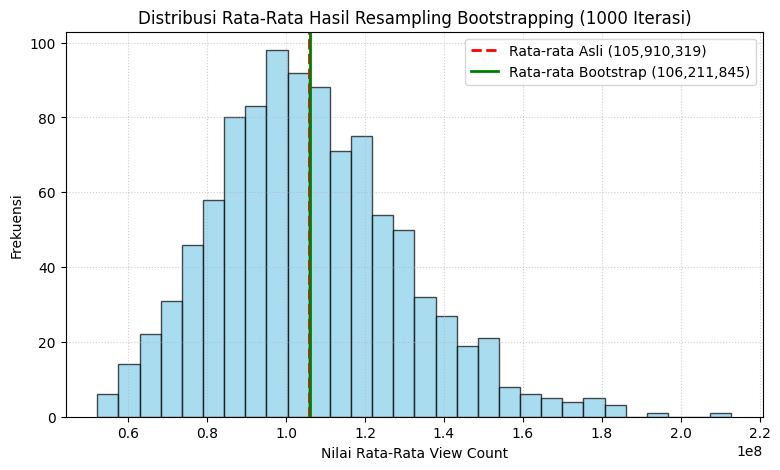

In [22]:
# Visualisasi Distribusi Bootstrapping
plt.figure(figsize=(9, 5))
plt.hist(bootstrap_means, bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(mean_sampel, color='red', linestyle='--', linewidth=2, label=f'Rata-rata Asli ({mean_sampel:,.0f})')
plt.axvline(mean_bootstrap, color='green', linestyle='-', linewidth=2, label=f'Rata-rata Bootstrap ({mean_bootstrap:,.0f})')
plt.title('Distribusi Rata-Rata Hasil Resampling Bootstrapping (1000 Iterasi)')
plt.xlabel('Nilai Rata-Rata View Count')
plt.ylabel('Frekuensi')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()